In [ ]:
'''Document the entire data preprocessing pipeline, including imputation, encoding, normalization, and feature engineering steps, to ensure reproducibility and enable future audits of the admission process.'''

'Create comprehensive markdown-based reports with visualizations, including feature importance plots and performance metrics, to facilitate clear communication with non-technical stakeholders'

In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


In [3]:
# load raw admission dataset
df = pd.read_csv('Adm.csv')
print(df.info())
print(df.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB
None
   Serial No.  GRE Score  ...                             University_Name  region
0           1        337  ... 

In [4]:
# feature engineering date components
df['Application_DateTime'] = pd.to_datetime(df['Application_DateTime'])
df['App_Month'] = df['Application_DateTime'].dt.month
df['App_Day'] = df['Application_DateTime'].dt.day
df['App_DayOfWeek'] = df['Application_DateTime'].dt.dayofweek
print(df[['Application_DateTime', 'App_Month', 'App_Day', 'App_DayOfWeek']].head())


  Application_DateTime  App_Month  App_Day  App_DayOfWeek
0  2022-01-01 09:00:00          1        1              5
1  2022-01-02 09:00:00          1        2              6
2  2022-01-04 09:00:00          1        4              1
3  2022-01-06 09:00:00          1        6              3
4  2022-01-08 09:00:00          1        8              5


In [5]:
# feature engineering academic index and recommendations
df['Academic_Index'] = (df['CGPA'] / 10.0) * 50.0 + (df['GRE Score'] / 340.0) * 50.0
df['Total_Recommendation'] = df['SOP'] + df['LOR']
print(df[['Academic_Index', 'Total_Recommendation']].head())


   Academic_Index  Total_Recommendation
0       97.808824                   9.0
1       91.997059                   8.5
2       86.470588                   6.5
3       90.702941                   6.0
4       87.226471                   5.0


In [6]:
# define feature subsets for pipeline
numeric_features = [
    'GRE Score', 'TOEFL Score', 'University Rating',
    'SOP', 'LOR', 'CGPA', 'Research',
    'Academic_Index', 'Total_Recommendation',
    'App_Month', 'App_Day', 'App_DayOfWeek'
]
categorical_features = ['region']
print("numeric features count:", len(numeric_features))
print("categorical features count:", len(categorical_features))


numeric features count: 12
categorical features count: 1


In [7]:
# construct imputation and scaling transformers
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
print("transformers constructed successfully")


transformers constructed successfully


In [8]:
# assemble full preprocessing column transformer pipeline
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])
print(preprocessor)


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['GRE Score', 'TOEFL Score',
                                  'University Rating', 'SOP', 'LOR', 'CGPA',
                                  'Research', 'Academic_Index',
                                  'Total_Recommendation', 'App_Month',
                                  'App_Day', 'App_DayOfWeek']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                    

In [9]:
# fit and transform data through reproducible pipeline
X = df[numeric_features + categorical_features]
X_processed = preprocessor.fit_transform(X)
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['encoder']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(cat_feature_names)
df_processed = pd.DataFrame(X_processed, columns=all_feature_names)
print("processed shape:", df_processed.shape)
print(df_processed.head())


processed shape: (1000, 18)
   GRE Score  TOEFL Score  ...  region_South  region_West
0   1.568729     1.498730  ...           0.0          0.0
1   0.599227     0.057139  ...           1.0          0.0
2   0.002610    -0.336022  ...           0.0          1.0
3   0.450073     0.450301  ...           0.0          0.0
4  -0.146544    -0.467075  ...           0.0          0.0

[5 rows x 18 columns]


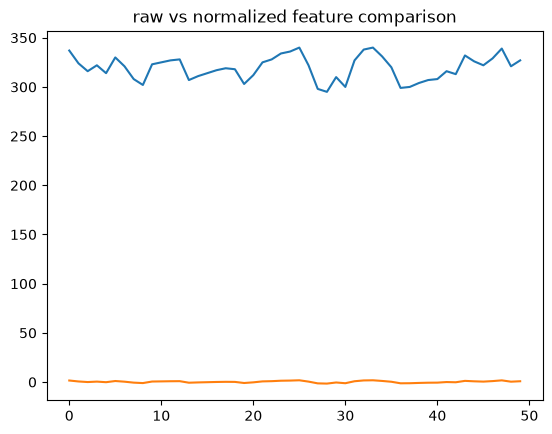

In [10]:
# plot feature distribution before and after normalization
plt.figure()
plt.plot(df['GRE Score'].head(50), label='raw gre score')
plt.plot(df_processed['GRE Score'].head(50), label='normalized gre score')
plt.title('raw vs normalized feature comparison')
plt.show()


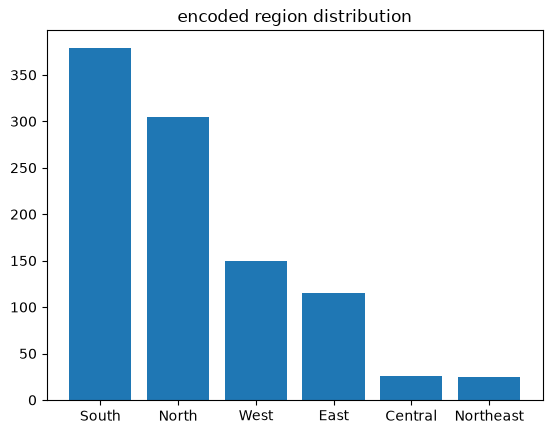

In [11]:
# plot categorical feature encoding summary
plt.figure()
region_counts = df['region'].value_counts()
plt.bar(region_counts.index, region_counts.values)
plt.title('encoded region distribution')
plt.show()


In [12]:
# audit and document pipeline configuration summary
audit_summary = {
    'total_samples': len(df),
    'num_features_in': len(numeric_features) + len(categorical_features),
    'num_features_out': df_processed.shape[1],
    'numeric_steps': [step[0] for step in preprocessor.named_transformers_['num'].steps],
    'categorical_steps': [step[0] for step in preprocessor.named_transformers_['cat'].steps],
    'missing_values_post_processing': int(df_processed.isnull().sum().sum())
}

print("=== pipeline audit documentation summary ===")
for k, v in audit_summary.items():
    print(f"{k}: {v}")


=== pipeline audit documentation summary ===
total_samples: 1000
num_features_in: 13
num_features_out: 18
numeric_steps: ['imputer', 'scaler']
categorical_steps: ['imputer', 'encoder']
missing_values_post_processing: 0
